In [1]:
from __future__ import annotations
import string 
import math
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Literal

In [16]:
@dataclass
class CouplingParameter:
    main_title: str = "QBO T–U coupling (5°S–5°N)"
    # Temperature metadata
    t_label: str = "T"
    t_units: str = "K"
    # Wind metadata
    u_label: str = "U"
    u_units: str = r"m s$^{-1}$"
    # Default fields in saved diagnostics
    t_field: Literal["qbo", "qbo_anom"] = "qbo_anom"
    u_field: Literal["qbo", "qbo_anom"] = "qbo"   # usually raw zonal wind QBO-like field


@dataclass
class SavedDiag2D:
    name: str
    x: xr.DataArray  # (time, plev)


class QboCouplingPlotter:
    """
    Diagnose T–U coupling / coherence from saved QBO-like diagnostics.

    Expected files:
      qbo_<exp>_ta_<period>.nc  (contains qbo or qbo_anom)
      qbo_<exp>_ua_<period>.nc  (contains qbo)

    Assumptions:
      - ta and ua share the same (time, plev) coordinates per experiment
      - no interpolation; exact match
    """

    def __init__(self, parameter: CouplingParameter):
        self.parameter = parameter

    # -------------------------
    # File helper
    # -------------------------
    @staticmethod
    def _diag_path(qbo_dir: Path, exp: str, tag: str, period: str) -> Path:
        return qbo_dir / f"qbo_{exp}_{tag}_{period}.nc"

    # -------------------------
    # Coordinate checks
    # -------------------------
    @staticmethod
    def _yyyymm_from_time(tvals) -> np.ndarray:
        out = np.empty(len(tvals), dtype=int)
        for i, t in enumerate(tvals):
            if hasattr(t, "year") and hasattr(t, "month"):
                out[i] = int(t.year) * 100 + int(t.month)
            else:
                s = np.datetime_as_string(t, unit="M")
                out[i] = int(s[:4]) * 100 + int(s[5:7])
        return out

    @staticmethod
    def _assert_same_time_and_plev(a: xr.DataArray, b: xr.DataArray):
        tdim_a, pdim_a = a.dims
        tdim_b, pdim_b = b.dims

        if a.sizes[tdim_a] != b.sizes[tdim_b]:
            raise ValueError(f"time length mismatch: {a.sizes[tdim_a]} vs {b.sizes[tdim_b]}")

        ma = QboCouplingPlotter._yyyymm_from_time(a[tdim_a].values)
        mb = QboCouplingPlotter._yyyymm_from_time(b[tdim_b].values)
        if not np.array_equal(ma, mb):
            bad = np.where(ma != mb)[0]
            i0 = int(bad[0]) if bad.size else -1
            raise ValueError(f"time mismatch at {i0}: {ma[i0]} vs {mb[i0]}")

        if pdim_a != pdim_b:
            raise ValueError(f"pressure dim mismatch: {pdim_a} vs {pdim_b}")

        pa = np.asarray(a[pdim_a].values, dtype=float)
        pb = np.asarray(b[pdim_b].values, dtype=float)
        if pa.shape != pb.shape or not np.array_equal(pa, pb):
            raise ValueError("pressure coordinate mismatch (values differ)")

    # -------------------------
    # Load saved 2D diagnostic
    # -------------------------
    def load_2d(
        self,
        in_path: str | Path,
        name: str | None = None,
        field: Literal["qbo", "qbo_anom"] = "qbo",
        compute_anom_if_missing: bool = True,
    ) -> SavedDiag2D:
        in_path = Path(in_path)
        ds = xr.open_dataset(in_path)
        exp_name = name or ds.attrs.get("name", in_path.stem)

        if field in ds:
            x = ds[field]
        else:
            if field == "qbo_anom" and compute_anom_if_missing and ("qbo" in ds):
                base = ds["qbo"]
                tdim = base.dims[0]
                if tdim not in base.coords:
                    raise ValueError(f"{in_path}: cannot compute anomaly without time coordinate")
                clim = base.groupby(f"{tdim}.month").mean(tdim)
                x = (base.groupby(f"{tdim}.month") - clim).rename("qbo_anom")
            else:
                raise KeyError(f"{in_path}: missing '{field}' (available={list(ds.data_vars)})")

        if x.ndim != 2:
            raise ValueError(f"{in_path}: {field} must be 2D (time,plev). dims={x.dims} shape={x.shape}")

        return SavedDiag2D(name=exp_name, x=x)

    # -------------------------
    # Core math: shear in log-pressure
    # -------------------------
    @staticmethod
    def shear_dlnp(u: xr.DataArray) -> xr.DataArray:
        """
        Compute S = dU/dln(p) using central differences in ln(p).
        Returns array with same dims (time, plev), using one-sided at ends.
        """
        tdim, pdim = u.dims
        p = np.asarray(u[pdim].values, dtype=float)
        if np.any(p <= 0):
            raise ValueError("pressure must be positive")
        ln_p = np.log(p)

        U = np.asarray(u.values, dtype=float)  # (time, p)
        nt, np_ = U.shape
        S = np.full_like(U, np.nan)

        # interior
        for j in range(1, np_ - 1):
            dln = ln_p[j + 1] - ln_p[j - 1]
            S[:, j] = (U[:, j + 1] - U[:, j - 1]) / dln

        # ends: one-sided
        S[:, 0] = (U[:, 1] - U[:, 0]) / (ln_p[1] - ln_p[0])
        S[:, -1] = (U[:, -1] - U[:, -2]) / (ln_p[-1] - ln_p[-2])

        out = xr.DataArray(
            S,
            dims=u.dims,
            coords=u.coords,
            name="dU_dlnp",
            attrs={"long_name": "vertical shear", "units": f"{u.attrs.get('units','')}/ln(hPa)"},
        )
        return out

    # -------------------------
    # Corr helpers
    # -------------------------
    @staticmethod
    def _corr_1d(a: np.ndarray, b: np.ndarray) -> float:
        m = np.isfinite(a) & np.isfinite(b)
        if np.count_nonzero(m) < 2:
            return np.nan
        aa = a[m]
        bb = b[m]
        if np.std(aa) == 0.0 or np.std(bb) == 0.0:
            return np.nan
        return float(np.corrcoef(aa, bb)[0, 1])

    @staticmethod
    def corr_profile_t(T: xr.DataArray, S: xr.DataArray) -> xr.DataArray:
        """
        r(p) = corr_t( T(t,p), S(t,p) )  -> returns 1D over plev
        """
        QboCouplingPlotter._assert_same_time_and_plev(T, S)
        tdim, pdim = T.dims
        p = np.asarray(T[pdim].values, dtype=float)
        r = np.full(p.shape, np.nan, dtype=float)

        TT = np.asarray(T.values, dtype=float)
        SS = np.asarray(S.values, dtype=float)
        for j in range(p.size):
            r[j] = QboCouplingPlotter._corr_1d(TT[:, j], SS[:, j])

        out = xr.DataArray(r, dims=(pdim,), coords={pdim: T[pdim]}, name="corr_T_shear")
        return out

    @staticmethod
    def layer_mean(x: xr.DataArray, pmin: float, pmax: float) -> xr.DataArray:
        """
        average over pressure layer [pmin, pmax] in hPa (inclusive-ish)
        """
        tdim, pdim = x.dims
        p = np.asarray(x[pdim].values, dtype=float)
        lo, hi = (min(pmin, pmax), max(pmin, pmax))
        m = (p >= lo) & (p <= hi)
        if not np.any(m):
            raise ValueError(f"no levels within [{lo},{hi}] hPa")
        return x.isel({pdim: np.where(m)[0]}).mean(pdim)

    # -------------------------
    # Public: load T and U for an experiment
    # -------------------------
    def load_TU(
        self,
        qbo_dir: str | Path,
        period: str,
        exp: str,
        t_tag: str = "ta",
        u_tag: str = "ua",
        t_field: Literal["qbo", "qbo_anom"] | None = None,
        u_field: Literal["qbo", "qbo_anom"] | None = None,
    ) -> tuple[xr.DataArray, xr.DataArray]:
        qbo_dir = Path(qbo_dir)
        t_field = t_field or self.parameter.t_field
        u_field = u_field or self.parameter.u_field

        ft = self._diag_path(qbo_dir, exp, t_tag, period)
        fu = self._diag_path(qbo_dir, exp, u_tag, period)

        if not ft.is_file():
            raise FileNotFoundError(f"Missing T diag: {ft}")
        if not fu.is_file():
            raise FileNotFoundError(f"Missing U diag: {fu}")

        T = self.load_2d(ft, name=exp, field=t_field).x
        U = self.load_2d(fu, name=exp, field=u_field).x

        self._assert_same_time_and_plev(T, U)
        return T, U

    # -------------------------
    # Public: plot r(p) profiles for all experiments (+ optional ref)
    # -------------------------
    def plot_T_shear_corr_profiles(
        self,
        qbo_dir: str | Path,
        period: str,
        exp_list: list[str],
        ref_exp: str | None = None,  # optional: plot ref curve too
        t_tag: str = "ta",
        u_tag: str = "ua",
        t_field: Literal["qbo", "qbo_anom"] | None = None,
        u_field: Literal["qbo", "qbo_anom"] | None = None,
        band_for_score: tuple[float, float] = (10.0, 70.0),
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        figsize: tuple[float, float] = (6.8, 7.8),
        dpi: int = 300,
        font_scale: float = 12,
        ylim: tuple[float, float] = (100, 1),
        xlim: tuple[float, float] = (-1, 1),
        skip_bad: bool = True,
        show: bool = True,
        style_map: dict[str, dict[str, Any]] | None = None,
        legend_outside: bool = True,
        fig_idx: int = 0, 
    ) -> tuple[Path | None, Path | None]:
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        style_map = style_map or {}

        title_fs  = int(round(font_scale * 1.05))
        label_fs  = int(round(font_scale * 1.00))
        tick_fs   = int(round(font_scale * 0.95))
        legend_fs = int(round(font_scale * 0.85))
        anno_fs   = int(round(font_scale * 0.85))
        
        def _line_kwargs(name: str) -> dict[str, Any]:
            """Return plotting kwargs for this experiment, with sensible defaults."""
            kw = dict(style_map.get(name, {}))  # copy
    
            # default emphasis if linewidth not explicitly given
            if "linewidth" not in kw:
                kw["linewidth"] = 2.2 if name in (ref_exp, "DARTOP", "ERA5OP") else 1.6
    
            # stable defaults if not provided
            kw.setdefault("linestyle", "-")
    
            return kw

        curves: list[tuple[str, np.ndarray, np.ndarray, float]] = []  # name, r, p, score

        # experiments
        for exp in exp_list:
            try:
                T, U = self.load_TU(qbo_dir, period, exp, t_tag=t_tag, u_tag=u_tag,
                                    t_field=t_field, u_field=u_field)
                S = self.shear_dlnp(U)
                rprof = self.corr_profile_t(T, S)  # 1D
                p = np.asarray(rprof[rprof.dims[0]].values, dtype=float)
                r = np.asarray(rprof.values, dtype=float)

                # score over band
                pmin, pmax = band_for_score
                m = (p >= min(pmin, pmax)) & (p <= max(pmin, pmax))
                score = float(np.nanmean(r[m])) if np.any(m) else np.nan

                # plot order: enforce decreasing p
                if p[0] < p[-1]:
                    p_plot = p[::-1]
                    r_plot = r[::-1]
                else:
                    p_plot = p
                    r_plot = r

                curves.append((exp, r_plot, p_plot, score))
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed T–shear corr for {exp}: {e} (skipped)")
                    continue
                raise

        # reference curve (optional)
        ref_curve = None
        if ref_exp is not None:
            try:
                T, U = self.load_TU(qbo_dir, period, ref_exp, t_tag=t_tag, u_tag=u_tag,
                                    t_field=t_field, u_field=u_field)
                S = self.shear_dlnp(U)
                rprof = self.corr_profile_t(T, S)
                p = np.asarray(rprof[rprof.dims[0]].values, dtype=float)
                r = np.asarray(rprof.values, dtype=float)

                pmin, pmax = band_for_score
                m = (p >= min(pmin, pmax)) & (p <= max(pmin, pmax))
                score = float(np.nanmean(r[m])) if np.any(m) else np.nan

                if p[0] < p[-1]:
                    ref_curve = (ref_exp, r[::-1], p[::-1], score)
                else:
                    ref_curve = (ref_exp, r, p, score)
            except Exception as e:
                if skip_bad:
                    print(f"WARNING: failed ref curve {ref_exp}: {e} (skipped)")
                else:
                    raise

        if len(curves) == 0 and ref_curve is None:
            raise ValueError("No curves to plot.")

        fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=False)

        # plot experiments
        for exp, r_plot, p_plot, score in curves:
            ax.plot(r_plot, p_plot, label=f"{exp}  (mean r={score:.2f})", **_line_kwargs(exp))

        # plot ref last (on top)
        if ref_curve is not None:
            name, r_plot, p_plot, score = ref_curve
            ax.plot(r_plot, p_plot, label=f"{name}  (mean r={score:.2f})", **_line_kwargs(name))

        ax.axvline(0.0, color="black", linewidth=0.2, alpha=0.5)

        panel_label = f"({string.ascii_lowercase[fig_idx+0]})"
        pmin, pmax = band_for_score
        ax.set_title(
            #f"{self.parameter.main_title}\n"
            fr"{panel_label} Corr[$T^\prime$, $\partial U$/$\partial lnp$] (mean: {min(pmin,pmax):g}–{max(pmin,pmax):g} hPa)",
            fontsize=title_fs, weight="normal", loc="left",
        )
        ax.set_xlabel("Correlation", fontsize=label_fs)
        ax.set_ylabel("hPa", fontsize=label_fs)
        ax.set_xlim(*xlim)
        ax.set_yscale("log")
        ax.set_ylim(*ylim)
        ax.grid(True, which="both", alpha=0.25)
        ax.tick_params(labelsize=tick_fs)

        # show band
        ax.axhspan(min(pmin, pmax), max(pmin, pmax), alpha=0.12)

        if legend_outside:
            ax.legend(loc="center left", bbox_to_anchor=(0.40, 0.28),
                      fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.78, bottom=0.12, top=0.95)
        else:
            ax.legend(loc="best", fontsize=legend_fs, frameon=False)
            fig.subplots_adjust(left=0.12, right=0.95, bottom=0.15, top=0.95)

        if png_name is None:
            png_name = f"TUcorr_tshear_{period}.png"
        if pdf_name is None:
            pdf_name = f"TUcorr_tshear_{period}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None
        if out_png is not None:
            fig.savefig(out_png, dpi=dpi, bbox_inches="tight")
            print("Wrote:", out_png)
        if out_pdf is not None:
            from matplotlib.backends.backend_pdf import PdfPages
            with PdfPages(out_pdf) as pdf:
                pdf.savefig(fig, bbox_inches="tight")
            print("Wrote:", out_pdf)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf

    # -------------------------
    # Public: scatter at one level or layer-mean
    # -------------------------
    def _nearest_level_index(self, p: np.ndarray, target_hpa: float) -> int:
        return int(np.argmin(np.abs(p - float(target_hpa))))

    def _layer_mask(self, p: np.ndarray, pmin: float, pmax: float) -> np.ndarray:
        lo, hi = (min(pmin, pmax), max(pmin, pmax))
        m = (p >= lo) & (p <= hi)
        return m

    def _extract_level_xy(self, T: xr.DataArray, S: xr.DataArray, target_hpa: float) -> tuple[np.ndarray, np.ndarray]:
        # one point per time (time series at nearest level)
        tdim, pdim = T.dims
        p = np.asarray(T[pdim].values, dtype=float)
        i0 = self._nearest_level_index(p, target_hpa)
        y = np.asarray(T.isel({pdim: i0}).values, dtype=float).ravel()
        x = np.asarray(S.isel({pdim: i0}).values, dtype=float).ravel()
        m = np.isfinite(x) & np.isfinite(y)
        return x[m], y[m]

    def _extract_layer_mean_xy(self, T: xr.DataArray, S: xr.DataArray, pmin: float, pmax: float) -> tuple[np.ndarray, np.ndarray]:
        # one point per time (layer-mean time series)
        tdim, pdim = T.dims
        p = np.asarray(T[pdim].values, dtype=float)
        mlev = self._layer_mask(p, pmin, pmax)
        if not np.any(mlev):
            raise ValueError(f"no levels within [{min(pmin,pmax)},{max(pmin,pmax)}] hPa")

        y = np.asarray(T.isel({pdim: np.where(mlev)[0]}).mean(pdim).values, dtype=float).ravel()
        x = np.asarray(S.isel({pdim: np.where(mlev)[0]}).mean(pdim).values, dtype=float).ravel()
        m = np.isfinite(x) & np.isfinite(y)
        return x[m], y[m]

    def _extract_layer_stacked_xy(self, T: xr.DataArray, S: xr.DataArray, pmin: float, pmax: float) -> tuple[np.ndarray, np.ndarray]:
        # many points: stack time×level in layer (illustrative)
        tdim, pdim = T.dims
        p = np.asarray(T[pdim].values, dtype=float)
        mlev = self._layer_mask(p, pmin, pmax)
        if not np.any(mlev):
            raise ValueError(f"no levels within [{min(pmin,pmax)},{max(pmin,pmax)}] hPa")

        Tsub = T.isel({pdim: np.where(mlev)[0]})
        Ssub = S.isel({pdim: np.where(mlev)[0]})
        y = np.asarray(Tsub.values, dtype=float).ravel()
        x = np.asarray(Ssub.values, dtype=float).ravel()
        m = np.isfinite(x) & np.isfinite(y)
        return x[m], y[m]

    def _fit_and_annotate(self, ax, anno_fs, color, x_mean: np.ndarray, y_mean: np.ndarray):
        # stats from layer-mean (or level) only: honest sample size (months)
        r = self._corr_1d(y_mean, x_mean)
        a, b = np.polyfit(x_mean, y_mean, 1) if x_mean.size >= 2 else (np.nan, np.nan)
        ax.text(
            0.04, 0.04,
            f"r={r:.2f}\nslope={a:.2g}",
            transform=ax.transAxes,
            ha="left", va="bottom",
            fontsize=anno_fs,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.7", alpha=0.85),
        )
        # draw fit line using mean-series fit
        if x_mean.size >= 2 and np.isfinite(a) and np.isfinite(b):
            xx = np.linspace(np.nanmin(x_mean), np.nanmax(x_mean), 60)
            ax.plot(xx, a * xx + b, color=color, linewidth=2.0, zorder=4)

    def plot_scatter_T_vs_shear(
        self,
        qbo_dir: str | Path,
        period: str,
        exp_list: list[str],
        ref_exp: str | None = None,
        t_tag: str = "ta",
        u_tag: str = "ua",
        t_field: Literal["qbo", "qbo_anom"] | None = None,
        u_field: Literal["qbo", "qbo_anom"] | None = None,
        # choose either a single level or a layer
        level_hpa: float | None = 30.0,
        layer_hpa: tuple[float, float] | None = None,  # e.g., (20, 50)
        # NEW: how to construct scatter points
        scatter_mode: Literal["layer_mean", "stacked_levels", "both"] = "both",
        output_dir: str | Path = "./",
        png_name: str | None = None,
        pdf_name: str | None = None,
        ncols: int = 3,
        nrows: int | None = None,  # NEW
        figsize: tuple[float, float] | None = None,
        dpi: int = 300,
        font_scale: float = 12,
        skip_bad: bool = True,
        show: bool = True,
        cloud_alpha: float = 0.45,  # NEW: transparency for stacked cloud
        cloud_size: float = 15,     # NEW
        cloud_color: str = "grey",
        mean_size: float = 28,      # NEW
        mean_alpha: float = 0.85,  # NEW: transparency for stacked cloud
        mean_color: str = "tab:red",
        fig_idx: int = 0,
    ) -> tuple[Path | None, Path | None]:
        """
        Scatter of T′ vs dU/dlnp.
        - level_hpa: use nearest level
        - layer_hpa: use pressure layer

        scatter_mode:
          - "layer_mean": use layer-mean (one point per time)
          - "stacked_levels": stack (time,level) points in layer (illustrative; not independent)
          - "both": plot stacked cloud + overlay layer-mean points; annotate stats from layer-mean
        """
        qbo_dir = Path(qbo_dir)
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        
        title_fs = int(round(font_scale * 1.05))
        label_fs = int(round(font_scale * 1.00))
        tick_fs  = int(round(font_scale * 0.95))
        leg_fs   = int(round(font_scale * 0.90))
        anno_fs  = int(round(font_scale * 0.90))
        
        names = list(exp_list)
        if ref_exp is not None:
            names = [ref_exp] + names

        npan = len(names)
        ncols = max(1, int(ncols))
        if nrows is None:
            nrows = int(math.ceil(npan / ncols))
        else:
            nrows = max(1, int(nrows))
            if nrows * ncols < npan:
                raise ValueError(f"Grid too small: need {npan} panels but got {nrows}x{ncols}")

        if figsize is None:
            figsize = (5.2 * ncols, 4.2 * nrows)

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
        axes = axes.ravel()
            
        for i, exp in enumerate(names):
            ax = axes[i]
            try:
                T, U = self.load_TU(
                    qbo_dir, period, exp, t_tag=t_tag, u_tag=u_tag,
                    t_field=t_field, u_field=u_field
                )
                S = self.shear_dlnp(U)

                if layer_hpa is not None:
                    pmin, pmax = layer_hpa
                    where = f"{min(pmin,pmax):g}–{max(pmin,pmax):g} hPa"

                    # mean time series (for stats)
                    x_mean, y_mean = self._extract_layer_mean_xy(T, S, pmin, pmax)

                    # cloud (optional)
                    if scatter_mode in ("stacked_levels", "both"):
                        x_cloud, y_cloud = self._extract_layer_stacked_xy(T, S, pmin, pmax)
                        ax.scatter(
                            x_cloud, y_cloud,
                            s=cloud_size,
                            alpha=cloud_alpha,
                            color=cloud_color,
                            zorder=1,
                        )
                    # overlay mean points (optional)
                    if scatter_mode in ("layer_mean", "both"):
                        ax.scatter(
                            x_mean, y_mean,
                            s=mean_size,
                            alpha=mean_alpha,
                            color=mean_color,
                            edgecolor="k",
                            linewidth=0.4,
                            zorder=3,
                        )
                    self._fit_and_annotate(ax, anno_fs, mean_color, x_mean, y_mean)

                else:
                    if level_hpa is None:
                        raise ValueError("either layer_hpa or level_hpa must be set")
                    where = f"~{level_hpa:g} hPa"

                    x_mean, y_mean = self._extract_level_xy(T, S, level_hpa)
                    # For single level, cloud==mean (so ignore stacked mode difference)
                    ax.scatter(x_mean, y_mean, s=mean_size, alpha=0.85)
                    self._fit_and_annotate(ax, anno_fs, mean_color, x_mean, y_mean)
                    
                panel_label = f"({string.ascii_lowercase[fig_idx+i]})"
                ax.set_title(f"{panel_label} {exp}", fontsize=title_fs, loc="left", weight="normal")
                ax.set_title(f"({where})", fontsize=title_fs, loc="right", weight="normal")
                ax.tick_params(labelsize=tick_fs)
                ax.grid(True, alpha=0.2)

                # axis labels
                if i % ncols == 0:
                    ax.set_ylabel(f"{self.parameter.t_label}′ ({self.parameter.t_units})", fontsize=title_fs)
                ax.set_xlabel(r"$\partial U/\partial \ln p$", fontsize=title_fs)

            except Exception as e:
                if skip_bad:
                    ax.axis("off")
                    print(f"WARNING: scatter failed for {exp}: {e} (skipped)")
                else:
                    raise

        for j in range(npan, nrows * ncols):
            axes[j].axis("off")

        #fig.suptitle(self.parameter.main_title, fontsize=int(round(font_scale * 1.2)))
        fig.tight_layout(rect=(0, 0, 1, 0.96))

        if png_name is None:
            tag = "layer" if layer_hpa is not None else "level"
            mode = scatter_mode
            png_name = f"TUscatter_tshear_{tag}_{mode}_{period}.png"
        if pdf_name is None:
            tag = "layer" if layer_hpa is not None else "level"
            mode = scatter_mode
            pdf_name = f"TUscatter_tshear_{tag}_{mode}_{period}.pdf"

        out_png = output_dir / png_name if png_name else None
        out_pdf = output_dir / pdf_name if pdf_name else None

        if out_png is not None:
            fig.savefig(out_png, dpi=dpi, bbox_inches="tight")
            print("Wrote:", out_png)
        if out_pdf is not None:
            from matplotlib.backends.backend_pdf import PdfPages
            with PdfPages(out_pdf) as pdf:
                pdf.savefig(fig, bbox_inches="tight")
            print("Wrote:", out_pdf)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return out_png, out_pdf

Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/TUcorr_tshear_2012-2013.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/TUcorr_tshear_2012-2013.pdf


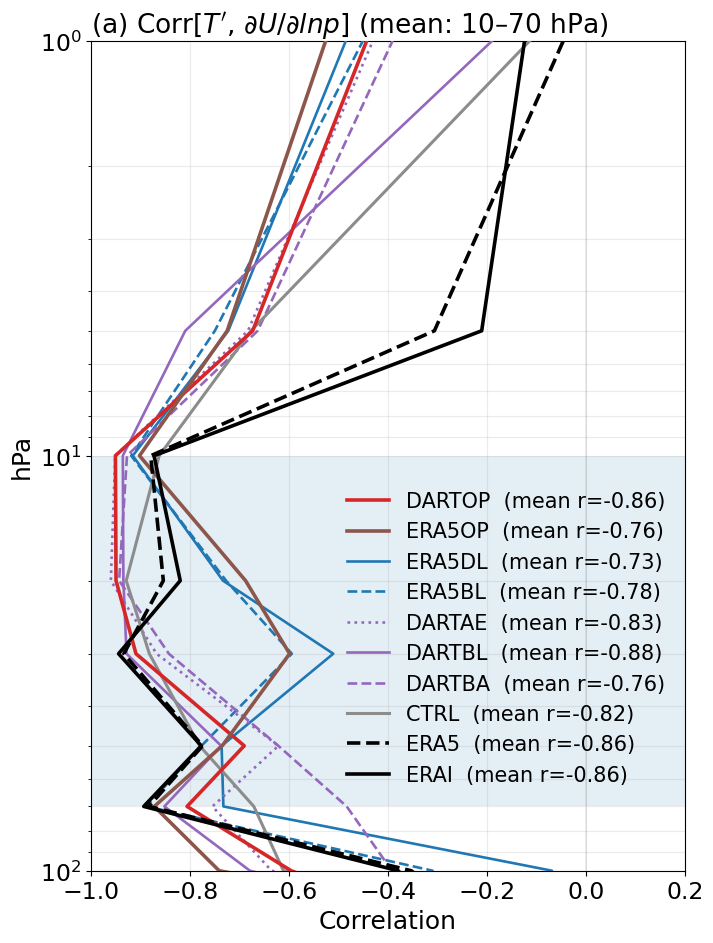

In [17]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    qbo_dir = Path(work_dir) / "figure_data" / "qbo"
    out_dir = Path(work_dir) / "qbo_analysis"
    out_dir.mkdir(parents=True, exist_ok=True)

    
    period = "2012-2013"
    ref_exp = "ERAI"
    #exp_list = ["DARTOP", "ERA5OP", "CTRL", "DARTBA", "ERA5"]
    exp_list = ["DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTAE", "DARTBL", "DARTBA", "CTRL", "ERA5"]

    # consistent colors + line styles across figures
    style_map = {
        # reference + baseline
        "ERAI":   dict(color="k",    linestyle="-",  linewidth=2.6, zorder=5),
        "ERA5":   dict(color="k",    linestyle="--",  linewidth=2.6, zorder=5),
        "CTRL":   dict(color="0.55", linestyle="-", linewidth=2.2, zorder=4),

        # key experiments (highlight)
        "DARTOP": dict(color="tab:red",   linestyle="-",  linewidth=2.6, zorder=5),
        "ERA5OP": dict(color="tab:brown", linestyle="-",  linewidth=2.6, zorder=5),

        # other ERA5-* (blue family)
        "ERA5DL": dict(color="tab:blue",  linestyle="-",  linewidth=1.9, zorder=3),
        "ERA5BL": dict(color="tab:blue",  linestyle="--", linewidth=1.9, zorder=3),

        # other DART-* (purple family)
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.9, zorder=3),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.9, zorder=3),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=1.9, zorder=3),
    }

    cp = CouplingParameter(main_title="QBO T–U coupling (5°S–5°N)",
                           t_field="qbo_anom", u_field="qbo")
    cplot = QboCouplingPlotter(cp)

    # 1) vertical profile of corr[T′, dU/dlnp]
    cplot.plot_T_shear_corr_profiles(
        qbo_dir=qbo_dir,
        period=period,
        exp_list=exp_list,
        ref_exp=ref_exp,
        band_for_score=(10, 70),
        output_dir=out_dir,
        show=True,
        font_scale=18,
        figsize=(9,10),
        xlim=(-1.0,0.2),
        ylim=(100,1),
        fig_idx = 0, 
        style_map=style_map,
    )
    

Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/TUscatter_tshear_layer_both_2012-2013.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/qbo_analysis/TUscatter_tshear_layer_both_2012-2013.pdf


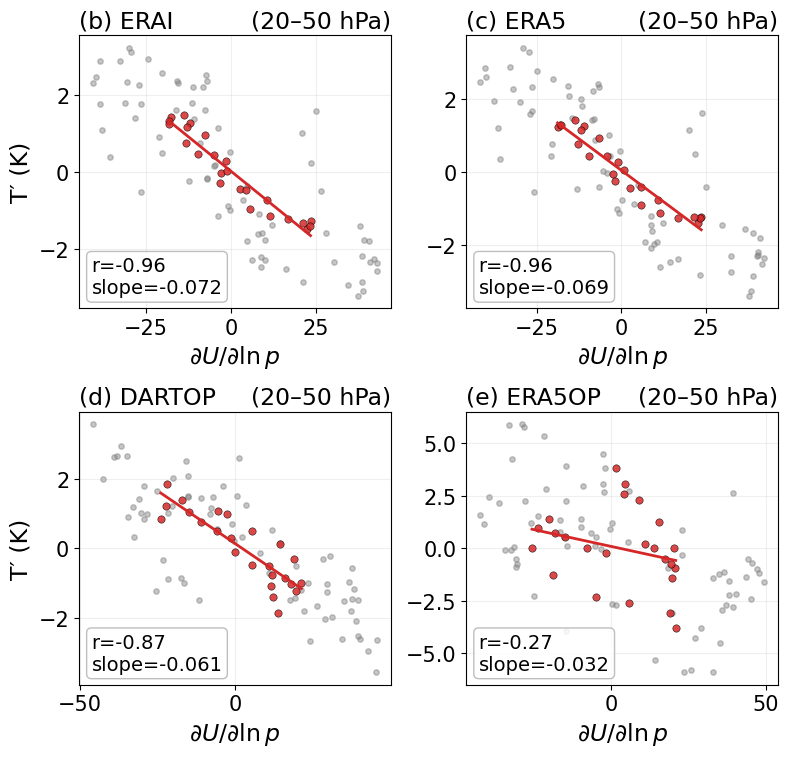

In [21]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    qbo_dir = Path(work_dir) / "figure_data" / "qbo"
    out_dir = Path(work_dir) / "qbo_analysis"
    out_dir.mkdir(parents=True, exist_ok=True)

    period = "2012-2013"
    ref_exp = "ERAI"
    exp_list = ["ERA5", "DARTOP", "ERA5OP"] #, "CTRL", "DARTBA"]

    cp = CouplingParameter(main_title="QBO T–U coupling (5°S–5°N)",
                           t_field="qbo_anom", u_field="qbo")
    cplot = QboCouplingPlotter(cp)

    # scatter at ~30 hPa (or use layer_hpa=(20,50))
    cplot.plot_scatter_T_vs_shear(
        qbo_dir=qbo_dir,
        period=period,
        exp_list=exp_list,
        ref_exp=ref_exp,
        layer_hpa=(20, 50),
        level_hpa=None,
        scatter_mode="both",   # cloud + mean overlay; stats from mean
        output_dir=out_dir,
        show=True,
        font_scale=16,
        figsize=(8,8),
        ncols=2,
        nrows=2,
        fig_idx = 1, 
    )
